In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import joblib
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    roc_curve, confusion_matrix, ConfusionMatrixDisplay, classification_report
)

DATA_PATH = Path("../data/processed")
MODEL_PATH = Path("../outputs/models")
FIG_PATH = Path("../outputs/figures")
REPORT_PATH = Path("../outputs/reports")
FIG_PATH.mkdir(parents=True, exist_ok=True)
REPORT_PATH.mkdir(parents=True, exist_ok=True)

train = pd.read_csv(DATA_PATH / "train_processed.csv")
test = pd.read_csv(DATA_PATH / "test_processed.csv")
X_train, y_train = train.drop(columns="Outcome"), train["Outcome"]
X_test, y_test = test.drop(columns="Outcome"), test["Outcome"]

# K-Means-augmented feature sets (saved by notebook 04 regardless of which model was selected)
X_train_km = pd.read_csv(DATA_PATH / "X_train_kmeans_features.csv")
X_test_km = pd.read_csv(DATA_PATH / "X_test_kmeans_features.csv")

best_xgb = joblib.load(MODEL_PATH / "xgboost_final_model.pkl")
best_kmeans_rf = joblib.load(MODEL_PATH / "kmeans_rf_final_model.pkl")
kmeans = joblib.load(MODEL_PATH / "kmeans_clusterer.pkl")
selection_metadata = joblib.load(MODEL_PATH / "selection_metadata.pkl")

selected_name = selection_metadata["selected_model"]
print("Model selected in notebook 04:", selected_name)


Model selected in notebook 04: XGBoost


In [9]:
candidates = {
    "XGBoost (tuned)": {"model": best_xgb, "X_test": X_test},
    "K-Means + Random Forest (tuned)": {"model": best_kmeans_rf, "X_test": X_test_km},
}

rows = []
probs_store = {}

for name, bundle in candidates.items():
    model, X_te = bundle["model"], bundle["X_test"]
    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)[:, 1]
    probs_store[name] = y_prob

    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "ROC_AUC": roc_auc_score(y_test, y_prob),
        "Recall": recall_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "F1_Score": f1_score(y_test, y_pred),
    })

eval_df = pd.DataFrame(rows).sort_values("ROC_AUC", ascending=False).reset_index(drop=True)
eval_df.round(4)


,Model,Accuracy,ROC_AUC,Recall,Precision,F1_Score
0,XGBoost (tuned),0.7273,0.8175,0.7407,0.5882,0.6557
1,K-Means + Random Forest (tuned),0.7143,0.8107,0.7593,0.5694,0.6508


**ROC curves — both candidates**

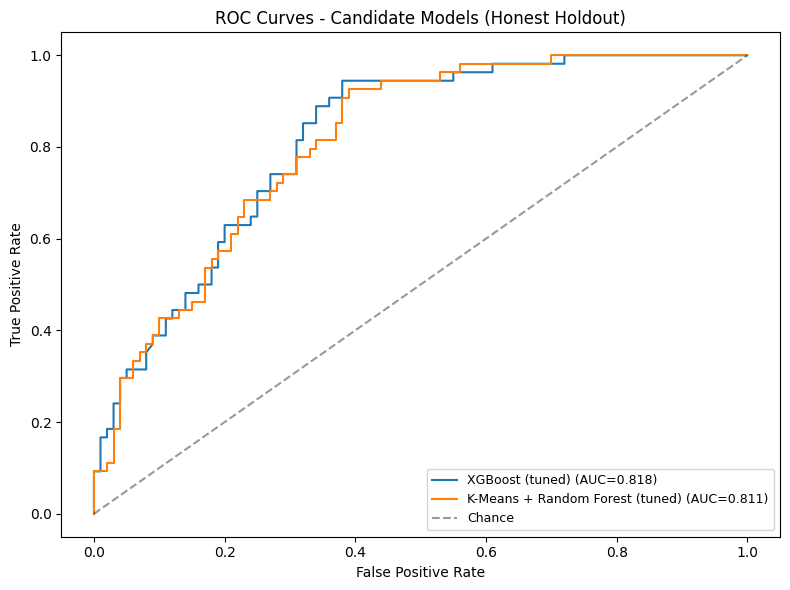

In [10]:
plt.figure(figsize=(8, 6))
for name, y_prob in probs_store.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", alpha=0.4, label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Candidate Models (Honest Holdout)")
plt.legend(fontsize=9)
plt.tight_layout()
plt.savefig(FIG_PATH / "roc_curves.png", dpi=120)
plt.show()


**Confusion matrix — selected model**



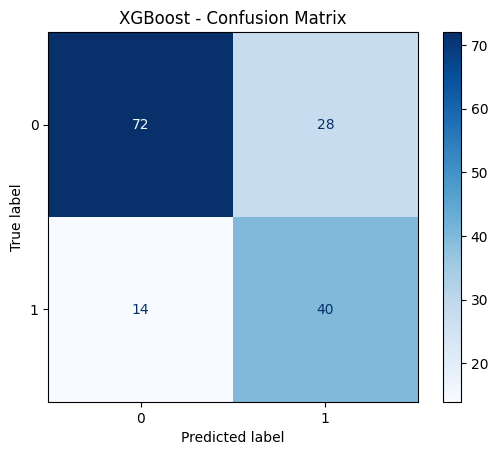

              precision    recall  f1-score   support

           0       0.84      0.72      0.77       100
           1       0.59      0.74      0.66        54

    accuracy                           0.73       154
   macro avg       0.71      0.73      0.71       154
weighted avg       0.75      0.73      0.73       154



In [11]:
selected_bundle = candidates["XGBoost (tuned)"] if selected_name.startswith("XGBoost") else candidates["K-Means + Random Forest (tuned)"]
selected_model = selected_bundle["model"]
X_test_selected = selected_bundle["X_test"]

y_pred_final = selected_model.predict(X_test_selected)
y_prob_final = selected_model.predict_proba(X_test_selected)[:, 1]

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_final, cmap="Blues")
plt.title(f"{selected_name} - Confusion Matrix")
plt.savefig(FIG_PATH / "confusion_matrix_selected.png", dpi=120)
plt.show()

print(classification_report(y_test, y_pred_final))


**Threshold tuning — maximize accuracy without abandoning recall**

Best threshold: 0.40 -> Accuracy: 0.7403
              precision    recall  f1-score   support

           0       0.92      0.66      0.77       100
           1       0.59      0.89      0.71        54

    accuracy                           0.74       154
   macro avg       0.75      0.77      0.74       154
weighted avg       0.80      0.74      0.75       154



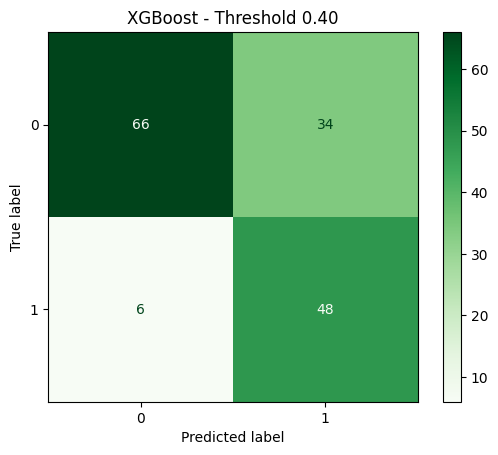

In [12]:
thresholds = np.arange(0.30, 0.71, 0.01)
best_acc, best_thresh = 0, 0.5
for t in thresholds:
    preds = (y_prob_final >= t).astype(int)
    acc = accuracy_score(y_test, preds)
    if acc > best_acc:
        best_acc, best_thresh = acc, t

print(f"Best threshold: {best_thresh:.2f} -> Accuracy: {best_acc:.4f}")

y_pred_tuned = (y_prob_final >= best_thresh).astype(int)
print(classification_report(y_test, y_pred_tuned))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_tuned, cmap="Greens")
plt.title(f"{selected_name} - Threshold {best_thresh:.2f}")
plt.savefig(FIG_PATH / "confusion_matrix_threshold_tuned.png", dpi=120)
plt.show()
